# Palmer Penguins Species Classification

## Project overview
This beginner-friendly machine-learning project predicts a penguin's species (Adelie, Chinstrap, or Gentoo) from four physical measurements: bill length, bill depth, flipper length, and body mass.

We compare two classifiers: **Decision Tree** and **K-Nearest Neighbors (KNN)**. The notebook explores the data, handles missing values, trains the models, and evaluates them with accuracy, classification reports, and confusion matrices.

## 1. Import libraries
The libraries below are used for data handling, visualization, preprocessing, model training, and evaluation.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Load the dataset
This CSV is hosted by the seaborn-data project. The original Palmer Penguins data were collected by the Palmer Station Long Term Ecological Research program. See the dataset links in the README.

In [3]:
dataset_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(dataset_url)

print("Dataset shape:", penguins.shape)
display(penguins.head())

Dataset shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 3. Explore and prepare the data
We use four numerical measurements as input features and `species` as the target. Rows with a missing species label cannot be used for supervised training, so those rows are removed. Missing measurement values are handled by a median imputer inside each model pipeline.

In [4]:
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

data = penguins[features + ["species"]].dropna(subset=["species"]).copy()
X = data[features]
y = data["species"]

print("Rows used:", len(data))
print("Missing feature values before imputation:")
display(X.isna().sum())
print("Species counts:")
display(y.value_counts())

Rows used: 344
Missing feature values before imputation:


bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Species counts:


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

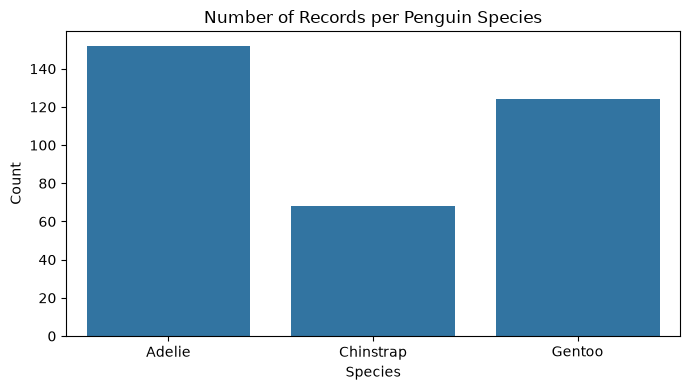

In [5]:
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="species")
plt.title("Number of Records per Penguin Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Split into training and testing data
The model learns from the training set. The test set is held back to evaluate how well it predicts unseen records. Stratification preserves the approximate class proportions in each split.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 275
Testing records: 69


## 5. Build and train the models
Both pipelines impute missing feature values using the median. KNN also standardizes the features because it uses distances; a Decision Tree does not require feature scaling.

In [7]:
decision_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

knn = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

models = {
    "Decision Tree": decision_tree,
    "KNN (k=5)": knn
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Decision Tree trained successfully.
KNN (k=5) trained successfully.


## 6. Evaluate and compare the models
Accuracy is the fraction of test records classified correctly. The classification report also shows precision, recall, and F1-score for each species.

In [8]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    accuracy = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": accuracy})
    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.3f} ({accuracy:.1%})")
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df)


Decision Tree
Accuracy: 0.986 (98.6%)
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        25

    accuracy                           0.99        69
   macro avg       0.99      0.99      0.99        69
weighted avg       0.99      0.99      0.99        69


KNN (k=5)
Accuracy: 1.000 (100.0%)
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



,Model,Accuracy
1,KNN (k=5),1.000000
0,Decision Tree,0.985507


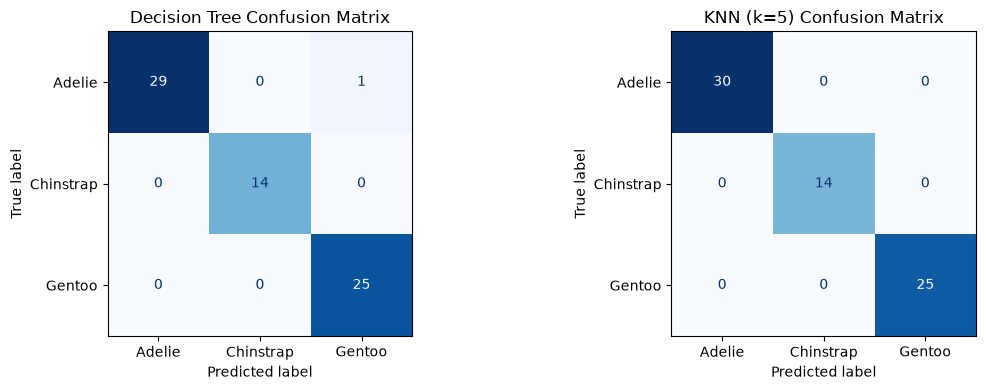

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        labels=model.classes_,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name} Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Conclusion
Compare the test accuracy and per-species scores above. The model with the higher test accuracy performed better on this particular train/test split; this does not guarantee it will be best on every dataset or split. The dataset is relatively small, so future work could use cross-validation and tune model settings.